In [27]:
import os
import json
import pandas as pd

PROJECT_DIR = r"C:\Users\rajva\Desktop\image-captioning Project"
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebook")

# Load processed captions
df = pd.read_pickle(
    os.path.join(NOTEBOOK_DIR, "processed_captions.pkl")
)

# Load vocabulary
with open(
    os.path.join(NOTEBOOK_DIR, "vocabulary.json"),
    "r",
    encoding="utf-8"
) as f:
    word_to_id = json.load(f)

id_to_word = {int(v): k for k, v in word_to_id.items()}

print("DataFrame:", df.shape)
print("Vocabulary:", len(word_to_id))
print("Columns:", df.columns.tolist())

DataFrame: (40000, 9)
Vocabulary: 12076
Columns: ['image', 'caption', 'split', 'clean_caption', 'tokens', 'tokens_with_special', 'token_ids', 'caption_length', 'padded_ids']


In [4]:
import os
import torch
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms


class ImageCaptionDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Load image
        image_path = os.path.join(self.image_dir, row["image"])
        image = Image.open(image_path).convert("RGB")

        # Apply image transformations
        if self.transform:
            image = self.transform(image)

        # Caption IDs
        caption = torch.tensor(
            row["padded_ids"],
            dtype=torch.long
        )

        return image, caption

In [5]:
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations created successfully.")

Image transformations created successfully.


In [6]:
from torch.utils.data import DataLoader

IMAGE_DIR = os.path.join(PROJECT_DIR, "data", "raw", "Images")

# Create datasets
train_dataset = ImageCaptionDataset(
    df[df["split"] == "train"],
    IMAGE_DIR,
    transform=image_transform
)

val_dataset = ImageCaptionDataset(
    df[df["split"] == "validation"],
    IMAGE_DIR,
    transform=image_transform
)

test_dataset = ImageCaptionDataset(
    df[df["split"] == "test"],
    IMAGE_DIR,
    transform=image_transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 30000
Validation samples: 5000
Test samples: 5000


In [7]:
# Get one batch from the training DataLoader
images, captions = next(iter(train_loader))

print("Images shape:", images.shape)
print("Captions shape:", captions.shape)

print("\nImage dtype:", images.dtype)
print("Caption dtype:", captions.dtype)

print("\nFirst image tensor range:")
print("Min:", images[0].min().item())
print("Max:", images[0].max().item())

print("\nFirst caption IDs:")
print(captions[0])

Images shape: torch.Size([32, 3, 224, 224])
Captions shape: torch.Size([32, 38])

Image dtype: torch.float32
Caption dtype: torch.int64

First image tensor range:
Min: -2.032280206680298
Max: 2.640000104904175

First caption IDs:
tensor([    1, 11227,  1335, 10453,  6956,    79, 10338,  2866,     2,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0])


In [8]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Load pretrained ResNet-50
weights = ResNet50_Weights.DEFAULT
resnet = resnet50(weights=weights)

print("ResNet-50 loaded successfully.")

ResNet-50 loaded successfully.


In [9]:
# Remove the final classification layer
resnet.fc = nn.Identity()

# Freeze ResNet parameters
for param in resnet.parameters():
    param.requires_grad = False

# Put model in evaluation mode
resnet.eval()

print("ResNet-50 encoder created.")
print("Output feature size:", 2048)

ResNet-50 encoder created.
Output feature size: 2048


In [10]:
# Move ResNet to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
resnet = resnet.to(device)

# Move images to the same device
images = images.to(device)

# Extract image features
with torch.no_grad():
    image_features = resnet(images)

print("Device:", device)
print("Input image shape:", images.shape)
print("Output feature shape:", image_features.shape)
print("Feature dtype:", image_features.dtype)

Device: cpu
Input image shape: torch.Size([32, 3, 224, 224])
Output feature shape: torch.Size([32, 2048])
Feature dtype: torch.float32


In [11]:
class CaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size=256,
        hidden_size=512,
        feature_size=2048
    ):
        super().__init__()

        # Convert ResNet features into LSTM hidden-state size
        self.feature_projection = nn.Linear(
            feature_size,
            hidden_size
        )

        # Convert word IDs into dense word embeddings
        self.embedding = nn.Embedding(
            vocab_size,
            embed_size
        )

        # LSTM for generating the caption sequence
        self.lstm = nn.LSTM(
            input_size=embed_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        # Convert LSTM output into vocabulary scores
        self.fc = nn.Linear(
            hidden_size,
            vocab_size
        )

    def forward(self, features, captions):
        # Project image features
        features = self.feature_projection(features)

        # Convert caption IDs to embeddings
        embeddings = self.embedding(captions)

        # Use image features as the initial hidden state
        h0 = features.unsqueeze(0)

        # Initial cell state
        c0 = torch.zeros_like(h0)

        # LSTM sequence processing
        outputs, _ = self.lstm(
            embeddings,
            (h0, c0)
        )

        # Predict vocabulary scores
        outputs = self.fc(outputs)

        return outputs


decoder = CaptionDecoder(
    vocab_size=len(word_to_id),
    embed_size=256,
    hidden_size=512,
    feature_size=2048
)

decoder = decoder.to(device)

print("Caption decoder created successfully.")
print("Vocabulary size:", len(word_to_id))
print("Embedding size:", 256)
print("Hidden size:", 512)

Caption decoder created successfully.
Vocabulary size: 12076
Embedding size: 256
Hidden size: 512


In [12]:
# Use the current batch of captions
captions = captions.to(device)

# Decoder receives captions without the final token
decoder_input = captions[:, :-1]

# Extract image features
with torch.no_grad():
    image_features = resnet(images)

# Pass image features + captions through decoder
outputs = decoder(image_features, decoder_input)

print("Decoder input shape:", decoder_input.shape)
print("Decoder output shape:", outputs.shape)

Decoder input shape: torch.Size([32, 37])
Decoder output shape: torch.Size([32, 37, 12076])


## use Cross Entropy Loss.

In [13]:
criterion = nn.CrossEntropyLoss(
    ignore_index=word_to_id["<PAD>"]
)

print("Loss function created successfully.")
print("Ignoring token:", word_to_id["<PAD>"])

Loss function created successfully.
Ignoring token: 0


In [14]:
import torch.optim as optim

optimizer = optim.Adam(
    decoder.parameters(),
    lr=0.001
)

print("Optimizer created successfully.")
print("Optimizer: Adam")
print("Learning rate:", 0.001)

Optimizer created successfully.
Optimizer: Adam
Learning rate: 0.001


In [15]:
# Get one training batch
images, captions = next(iter(train_loader))

images = images.to(device)
captions = captions.to(device)

# Decoder input: remove <END>
decoder_input = captions[:, :-1]

# Target: remove <START>
targets = captions[:, 1:]

# Extract image features
with torch.no_grad():
    image_features = resnet(images)

# Clear previous gradients
optimizer.zero_grad()

# Forward pass
outputs = decoder(image_features, decoder_input)

# Reshape for CrossEntropyLoss
loss = criterion(
    outputs.reshape(-1, outputs.size(-1)),
    targets.reshape(-1)
)

# Backpropagation
loss.backward()

# Update decoder parameters
optimizer.step()

print("First training step completed.")
print("Loss:", loss.item())

First training step completed.
Loss: 9.41150951385498


In [16]:
##Create a Proper Training Function

In [17]:
def train_one_epoch(
    encoder,
    decoder,
    dataloader,
    criterion,
    optimizer,
    device
):
    encoder.eval()
    decoder.train()

    total_loss = 0

    for images, captions in dataloader:

        images = images.to(device)
        captions = captions.to(device)

        # Input: <START> word1 word2 ...
        decoder_input = captions[:, :-1]

        # Target: word1 word2 ... <END>
        targets = captions[:, 1:]

        # Extract image features
        with torch.no_grad():
            features = encoder(images)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = decoder(features, decoder_input)

        # Calculate loss
        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            targets.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Update decoder
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(dataloader)

    return average_loss


print("Training function created successfully.")

Training function created successfully.


In [18]:
def validate_one_epoch(
    encoder,
    decoder,
    dataloader,
    criterion,
    device
):
    encoder.eval()
    decoder.eval()

    total_loss = 0

    with torch.no_grad():

        for images, captions in dataloader:

            images = images.to(device)
            captions = captions.to(device)

            # Decoder input: <START> word1 word2 ...
            decoder_input = captions[:, :-1]

            # Target: word1 word2 ... <END>
            targets = captions[:, 1:]

            # Extract image features
            features = encoder(images)

            # Forward pass
            outputs = decoder(
                features,
                decoder_input
            )

            # Calculate loss
            loss = criterion(
                outputs.reshape(-1, outputs.size(-1)),
                targets.reshape(-1)
            )

            total_loss += loss.item()

    average_loss = total_loss / len(dataloader)

    return average_loss


print("Validation function created successfully.")

Validation function created successfully.


In [19]:
import os
import torch

# Training configuration
num_epochs = 5

best_val_loss = float("inf")

# Folder to save model checkpoints
CHECKPOINT_DIR = os.path.join(NOTEBOOK_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Store training history
train_losses = []
val_losses = []

print("Training configuration ready.")
print("Device:", device)
print("Epochs:", num_epochs)
print("Checkpoint folder:", CHECKPOINT_DIR)

Training configuration ready.
Device: cpu
Epochs: 5
Checkpoint folder: C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints


In [21]:
import torch
import os

FEATURE_DIR = os.path.join(NOTEBOOK_DIR, "cached_features")
os.makedirs(FEATURE_DIR, exist_ok=True)

train_feature_path = os.path.join(
    FEATURE_DIR,
    "train_features.pt"
)

resnet.eval()

train_features = []
train_captions = []

with torch.no_grad():

    for batch_idx, (images, captions) in enumerate(train_loader):

        images = images.to(device)

        # Extract ResNet-50 features
        features = resnet(images)

        train_features.append(features.cpu())
        train_captions.append(captions)

        # Progress
        if (batch_idx + 1) % 50 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(train_loader)} batches"
            )

# Combine all batches
train_features = torch.cat(train_features, dim=0)
train_captions = torch.cat(train_captions, dim=0)

# Save to disk
torch.save(
    {
        "features": train_features,
        "captions": train_captions
    },
    train_feature_path
)

print("\nTraining features cached successfully.")
print("Features shape:", train_features.shape)
print("Captions shape:", train_captions.shape)
print("Saved to:", train_feature_path)

Processed 50/938 batches
Processed 100/938 batches
Processed 150/938 batches
Processed 200/938 batches
Processed 250/938 batches
Processed 300/938 batches
Processed 350/938 batches
Processed 400/938 batches
Processed 450/938 batches
Processed 500/938 batches
Processed 550/938 batches
Processed 600/938 batches
Processed 650/938 batches
Processed 700/938 batches
Processed 750/938 batches
Processed 800/938 batches
Processed 850/938 batches
Processed 900/938 batches

Training features cached successfully.
Features shape: torch.Size([30000, 2048])
Captions shape: torch.Size([30000, 38])
Saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\train_features.pt


## Cache validation features

In [31]:
import torch
import os

val_feature_path = os.path.join(
    FEATURE_DIR,
    "val_features.pt"
)

resnet.eval()

val_features = []
val_captions = []

with torch.no_grad():

    for batch_idx, (images, captions) in enumerate(val_loader):

        images = images.to(device)

        features = resnet(images)

        val_features.append(features.cpu())
        val_captions.append(captions)

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(val_loader)} batches"
            )

val_features = torch.cat(val_features, dim=0)
val_captions = torch.cat(val_captions, dim=0)

torch.save(
    {
        "features": val_features,
        "captions": val_captions
    },
    val_feature_path
)

print("\nValidation features cached successfully.")
print("Features shape:", val_features.shape)
print("Captions shape:", val_captions.shape)
print("Saved to:", val_feature_path)

Processed 50/157 batches
Processed 100/157 batches
Processed 150/157 batches

Validation features cached successfully.
Features shape: torch.Size([5000, 2048])
Captions shape: torch.Size([5000, 38])
Saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\val_features.pt


## Cache Test Features

In [32]:
import torch
import os

test_feature_path = os.path.join(
    FEATURE_DIR,
    "test_features.pt"
)

resnet.eval()

test_features = []
test_captions = []

with torch.no_grad():

    for batch_idx, (images, captions) in enumerate(test_loader):

        images = images.to(device)

        features = resnet(images)

        test_features.append(features.cpu())
        test_captions.append(captions)

        if (batch_idx + 1) % 50 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(test_loader)} batches"
            )

test_features = torch.cat(test_features, dim=0)
test_captions = torch.cat(test_captions, dim=0)

torch.save(
    {
        "features": test_features,
        "captions": test_captions
    },
    test_feature_path
)

print("\nTest features cached successfully.")
print("Features shape:", test_features.shape)
print("Captions shape:", test_captions.shape)
print("Saved to:", test_feature_path)

Processed 50/157 batches
Processed 100/157 batches
Processed 150/157 batches

Test features cached successfully.
Features shape: torch.Size([5000, 2048])
Captions shape: torch.Size([5000, 38])
Saved to: C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\test_features.pt


## Feature-Based Dataset

In [33]:
from torch.utils.data import Dataset, DataLoader

class FeatureCaptionDataset(Dataset):

    def __init__(self, feature_file):
        data = torch.load(feature_file)

        self.features = data["features"]
        self.captions = data["captions"]

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.captions[idx]


# Create datasets
train_feature_dataset = FeatureCaptionDataset(train_feature_path)
val_feature_dataset = FeatureCaptionDataset(val_feature_path)
test_feature_dataset = FeatureCaptionDataset(test_feature_path)


print("Feature datasets created successfully.")
print("Train samples:", len(train_feature_dataset))
print("Validation samples:", len(val_feature_dataset))
print("Test samples:", len(test_feature_dataset))

Feature datasets created successfully.
Train samples: 30000
Validation samples: 5000
Test samples: 5000


## Create Feature DataLoaders

In [34]:
from torch.utils.data import DataLoader

train_feature_loader = DataLoader(
    train_feature_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_feature_loader = DataLoader(
    val_feature_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

test_feature_loader = DataLoader(
    test_feature_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Feature DataLoaders created successfully.")

print("Train batches:", len(train_feature_loader))
print("Validation batches:", len(val_feature_loader))
print("Test batches:", len(test_feature_loader))

Feature DataLoaders created successfully.
Train batches: 938
Validation batches: 157
Test batches: 157


## Verify Feature Batch


In [35]:
features, captions = next(iter(train_feature_loader))

print("Features shape:", features.shape)
print("Captions shape:", captions.shape)

print("\nFeature dtype:", features.dtype)
print("Caption dtype:", captions.dtype)

print("\nFeature range:")
print("Min:", features.min().item())
print("Max:", features.max().item())

print("\nFirst caption IDs:")
print(captions[0])

Features shape: torch.Size([32, 2048])
Captions shape: torch.Size([32, 38])

Feature dtype: torch.float32
Caption dtype: torch.int64

Feature range:
Min: 0.0
Max: 10.93127155303955

First caption IDs:
tensor([   1,   79,  753, 6166, 5785, 5027, 9357, 6913,   79, 8248,    2,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0])


In [36]:
#Feature-Based Training Function
def train_decoder_one_epoch(
    decoder,
    dataloader,
    criterion,
    optimizer,
    device
):
    decoder.train()

    total_loss = 0

    for features, captions in dataloader:

        features = features.to(device)
        captions = captions.to(device)

        # Input: <START> + words
        decoder_input = captions[:, :-1]

        # Target: words + <END>
        targets = captions[:, 1:]

        optimizer.zero_grad()

        # Generate predictions
        outputs = decoder(
            features,
            decoder_input
        )

        # Calculate loss
        loss = criterion(
            outputs.reshape(-1, outputs.size(-1)),
            targets.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Update decoder parameters
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(dataloader)

    return average_loss


print("Feature-based training function created successfully.")

Feature-based training function created successfully.


In [37]:
#Feature-Based Validation Function
def validate_decoder_one_epoch(
    decoder,
    dataloader,
    criterion,
    device
):
    decoder.eval()

    total_loss = 0

    with torch.no_grad():

        for features, captions in dataloader:

            features = features.to(device)
            captions = captions.to(device)

            # Input: <START> + words
            decoder_input = captions[:, :-1]

            # Target: words + <END>
            targets = captions[:, 1:]

            # Generate predictions
            outputs = decoder(
                features,
                decoder_input
            )

            # Calculate loss
            loss = criterion(
                outputs.reshape(-1, outputs.size(-1)),
                targets.reshape(-1)
            )

            total_loss += loss.item()

    average_loss = total_loss / len(dataloader)

    return average_loss


print("Feature-based validation function created successfully.")

Feature-based validation function created successfully.


In [38]:
#Reset Decoder and Optimizer
import torch.optim as optim

# Create a fresh decoder
decoder = CaptionDecoder(
    vocab_size=len(word_to_id),
    embed_size=256,
    hidden_size=512,
    feature_size=2048
)

decoder = decoder.to(device)

# Create a fresh optimizer
optimizer = optim.Adam(
    decoder.parameters(),
    lr=0.001
)

print("Fresh decoder created.")
print("Fresh optimizer created.")
print("Learning rate:", 0.001)
print("Device:", device)

Fresh decoder created.
Fresh optimizer created.
Learning rate: 0.001
Device: cpu


Training Configuration

In [39]:
import os

num_epochs = 5
best_val_loss = float("inf")

CHECKPOINT_DIR = os.path.join(
    NOTEBOOK_DIR,
    "checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

train_losses = []
val_losses = []

print("Baseline training configuration ready.")
print("Model: ResNet-50 + LSTM")
print("Training mode: Cached features")
print("Epochs:", num_epochs)
print("Batch size:", 32)
print("Learning rate:", 0.001)
print("Device:", device)
print("Checkpoint folder:", CHECKPOINT_DIR)

Baseline training configuration ready.
Model: ResNet-50 + LSTM
Training mode: Cached features
Epochs: 5
Batch size: 32
Learning rate: 0.001
Device: cpu
Checkpoint folder: C:\Users\rajva\Desktop\image-captioning Project\notebook\checkpoints


## Train Epoch 1

In [40]:
import time

start_time = time.time()

print("Starting Epoch 1...")
print("-" * 40)

train_loss = train_decoder_one_epoch(
    decoder,
    train_feature_loader,
    criterion,
    optimizer,
    device
)

val_loss = validate_decoder_one_epoch(
    decoder,
    val_feature_loader,
    criterion,
    device
)

elapsed_time = time.time() - start_time

train_losses.append(train_loss)
val_losses.append(val_loss)

print("\nEpoch 1 completed.")
print(f"Training Loss:   {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Time taken:      {elapsed_time / 60:.2f} minutes")

Starting Epoch 1...
----------------------------------------

Epoch 1 completed.
Training Loss:   3.9966
Validation Loss: 3.5188
Time taken:      7.01 minutes


In [41]:
import time
import torch
import os

for epoch in range(1, num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 40)

    start_time = time.time()

    train_loss = train_decoder_one_epoch(
        decoder,
        train_feature_loader,
        criterion,
        optimizer,
        device
    )

    val_loss = validate_decoder_one_epoch(
        decoder,
        val_feature_loader,
        criterion,
        device
    )

    elapsed_time = time.time() - start_time

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Training Loss:   {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Time taken:      {elapsed_time / 60:.2f} minutes")

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_baseline_model.pth"
        )

        torch.save({
            "epoch": epoch + 1,
            "decoder_state_dict": decoder.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "vocab_size": len(word_to_id)
        }, checkpoint_path)

        print("✓ Best model saved.")

print("\nBaseline training completed.")


Epoch 2/5
----------------------------------------
Training Loss:   3.0910
Validation Loss: 3.2956
Time taken:      13.36 minutes
✓ Best model saved.

Epoch 3/5
----------------------------------------
Training Loss:   2.6709
Validation Loss: 3.2414
Time taken:      13.31 minutes
✓ Best model saved.

Epoch 4/5
----------------------------------------
Training Loss:   2.3399
Validation Loss: 3.2404
Time taken:      7.21 minutes
✓ Best model saved.

Epoch 5/5
----------------------------------------
Training Loss:   2.0605
Validation Loss: 3.3117
Time taken:      7.30 minutes

Baseline training completed.


## Load the Best Baseline Model

In [42]:
import torch
import os

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_baseline_model.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

decoder.load_state_dict(
    checkpoint["decoder_state_dict"]
)

print("Best baseline model loaded successfully.")
print("Best epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])
print("Validation loss:", checkpoint["val_loss"])

Best baseline model loaded successfully.
Best epoch: 4
Training loss: 2.3398847834133645
Validation loss: 3.240390560429567


In [43]:
def generate_caption(
    decoder,
    image_feature,
    word_to_id,
    id_to_word,
    device,
    max_length=38
):
    decoder.eval()

    # Make sure feature has batch dimension
    if image_feature.dim() == 1:
        image_feature = image_feature.unsqueeze(0)

    image_feature = image_feature.to(device)

    # Start with <START>
    start_id = word_to_id["<START>"]
    end_id = word_to_id["<END>"]

    current_token = torch.tensor(
        [[start_id]],
        dtype=torch.long,
        device=device
    )

    generated_ids = [start_id]

    # Generate one word at a time
    with torch.no_grad():

        # Initialize hidden state from image
        projected_feature = decoder.feature_projection(
            image_feature
        )

        h = projected_feature.unsqueeze(0)
        c = torch.zeros_like(h)

        for _ in range(max_length - 1):

            # Convert current word ID to embedding
            embedding = decoder.embedding(current_token)

            # Pass through LSTM
            output, (h, c) = decoder.lstm(
                embedding,
                (h, c)
            )

            # Convert LSTM output to vocabulary scores
            scores = decoder.fc(output[:, -1, :])

            # Select most probable word
            predicted_id = scores.argmax(dim=-1).item()

            # Stop if <END> is generated
            if predicted_id == end_id:
                generated_ids.append(predicted_id)
                break

            generated_ids.append(predicted_id)

            # Use predicted word as next input
            current_token = torch.tensor(
                [[predicted_id]],
                dtype=torch.long,
                device=device
            )

    # Convert IDs to words
    words = []

    for token_id in generated_ids:
        word = id_to_word[token_id]

        if word in ["<START>", "<END>", "<PAD>"]:
            continue

        words.append(word)

    caption = " ".join(words)

    return caption


print("Caption generation function created successfully.")

Caption generation function created successfully.


In [44]:
##Generate a Caption for a Test Image

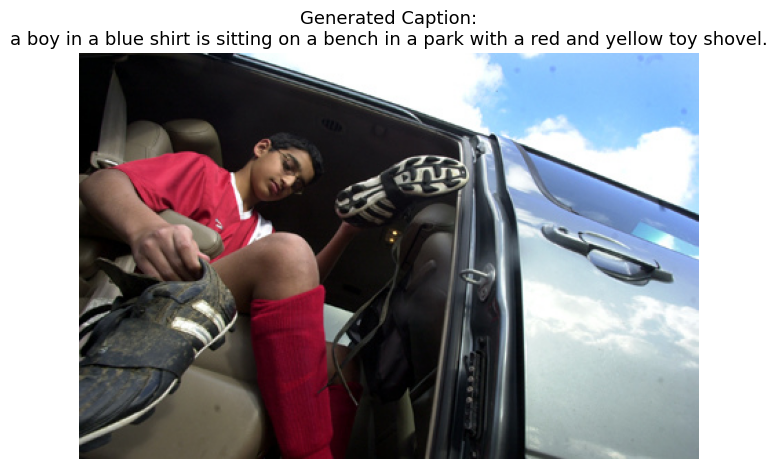

Image: 114051287_dd85625a04.jpg
Generated Caption: a boy in a blue shirt is sitting on a bench in a park with a red and yellow toy shovel.


In [51]:
import matplotlib.pyplot as plt
from PIL import Image

# Select one test image
test_row = test_dataset.df.iloc[56]

image_name = test_row["image"]
image_path = os.path.join(IMAGE_DIR, image_name)

# Load original image
image = Image.open(image_path).convert("RGB")

# Preprocess image for ResNet-50
image_tensor = image_transform(image).unsqueeze(0).to(device)

# Extract image features
with torch.no_grad():
    image_feature = resnet(image_tensor)

# Generate caption
generated_caption = generate_caption(
    decoder=decoder,
    image_feature=image_feature,
    word_to_id=word_to_id,
    id_to_word=id_to_word,
    device=device,
    max_length=38
)

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    "Generated Caption:\n" + generated_caption,
    fontsize=13
)
plt.show()

print("Image:", image_name)
print("Generated Caption:", generated_caption)

In [52]:
# Check the 5 human reference captions for the selected image

image_name = test_row["image"]

reference_captions = test_dataset.df[
    test_dataset.df["image"] == image_name
]["caption"].tolist()

print("Image:", image_name)
print("\nHuman Reference Captions:")

for i, caption in enumerate(reference_captions, 1):
    print(f"{i}. {caption}")

Image: 114051287_dd85625a04.jpg

Human Reference Captions:
1. A boy dressed in soccer attire and holding his shoes getting out of a car .
2. A boy in a red soccer strip is holding his boots in his hand whilst stepping out of a car .
3. A boy in glasses is wearing a red shirt .
4. A child getting out of the car wearing soccer shoes .
5. A young boy gets out of the van and prepares his shoes for wear during a soccer game .


In [53]:
# Get unique test images
test_images = test_dataset.df["image"].unique()

print("Total test caption rows:", len(test_dataset.df))
print("Unique test images:", len(test_images))
print("Captions per image:", len(test_dataset.df) // len(test_images))

Total test caption rows: 5000
Unique test images: 1000
Captions per image: 5


In [54]:
##Create 5 Reference Captions per Test Image
# Create reference captions for each unique test image

test_references = {}

for image_name in test_images:
    captions = test_dataset.df[
        test_dataset.df["image"] == image_name
    ]["clean_caption"].tolist()

    test_references[image_name] = captions

# Verify one example
sample_image = test_images[0]

print("Sample image:", sample_image)
print("Number of reference captions:",
      len(test_references[sample_image]))

for i, caption in enumerate(
    test_references[sample_image], 1
):
    print(f"{i}. {caption}")

Sample image: 1056338697_4f7d7ce270.jpg
Number of reference captions: 5
1. a blond woman in a blue shirt appears to wait for a ride.
2. a blond woman is on the street hailing a taxi.
3. a woman is signaling is to traffic, as seen from behind.
4. a woman with blonde hair wearing a blue tube top is waving on the side of the street.
5. the woman in the blue dress is holding out her arm at oncoming traffic.


## Prepare One Feature per Unique Test Image

In [55]:
# Find the first occurrence of each unique test image
unique_image_indices = (
    test_dataset.df
    .drop_duplicates("image")
    .index
    .tolist()
)

# Load cached test features
test_feature_data = torch.load(
    test_feature_path,
    map_location=device
)

all_test_features = test_feature_data["features"]

# Select one feature for each unique image
unique_test_features = all_test_features[
    unique_image_indices
]

print("All cached test features:",
      all_test_features.shape)

print("Unique test images:",
      len(test_images))

print("Unique test features:",
      unique_test_features.shape)

print("Number of reference captions for first image:",
      len(test_references[test_images[0]]))

All cached test features: torch.Size([5000, 2048])
Unique test images: 1000
Unique test features: torch.Size([1000, 2048])
Number of reference captions for first image: 5


## Generate Captions for All 1,000 Test Images

In [56]:
import time

decoder.eval()

generated_captions = {}

start_time = time.time()

with torch.no_grad():

    for i, image_name in enumerate(test_images):

        # Get one feature for this image
        image_feature = unique_test_features[i]

        # Generate caption
        caption = generate_caption(
            decoder=decoder,
            image_feature=image_feature,
            word_to_id=word_to_id,
            id_to_word=id_to_word,
            device=device,
            max_length=38
        )

        generated_captions[image_name] = caption

        # Progress update
        if (i + 1) % 100 == 0:
            print(
                f"Generated {i + 1}/{len(test_images)} captions"
            )

elapsed_time = time.time() - start_time

print("\nCaption generation completed.")
print(f"Total images: {len(generated_captions)}")
print(f"Time taken: {elapsed_time / 60:.2f} minutes")

Generated 100/1000 captions
Generated 200/1000 captions
Generated 300/1000 captions
Generated 400/1000 captions
Generated 500/1000 captions
Generated 600/1000 captions
Generated 700/1000 captions
Generated 800/1000 captions
Generated 900/1000 captions
Generated 1000/1000 captions

Caption generation completed.
Total images: 1000
Time taken: 0.80 minutes


## Check Generated Captions

In [58]:
# Display 5 generated captions with their human references

for i, image_name in enumerate(test_images[13:20], 1):

    print("=" * 80)
    print(f"Example {i}")
    print("Image:", image_name)

    print("\nGenerated Caption:")
    print(generated_captions[image_name])

    print("\nHuman Reference Captions:")

    for j, reference in enumerate(
        test_references[image_name], 1
    ):
        print(f"{j}. {reference}")

Example 1
Image: 1167669558_87a8a467d6.jpg

Generated Caption:
a man in a black shirt is holding a cup.

Human Reference Captions:
1. a man in yellow grimaces.
2. a man wearing a yellow shirt with a dramatic look on his face
3. the man in the yellow t-shirt is pulling a large grin on his face.
4. there is a man, wearing a yellow shirt, and grimacing.
5. this man is smiling very big at the camera.
Example 2
Image: 1174525839_7c1e6cfa86.jpg

Generated Caption:
a boy in a wetsuit is surfing on a wave.

Human Reference Captions:
1. a girl in blue is jumping on the shore as small waves approach her.
2. a girl leaps into the air while standing by the ocean.
3. a young, long-haired, girl on the beach, is jumping in the air.
4. the girl is running into the ocean from the shore.
5. the girls is jumping into the air on the beach.
Example 3
Image: 1174629344_a2e1a2bdbf.jpg

Generated Caption:
a group of people are standing on a street in a park

Human Reference Captions:
1. a crowd of people walk

## Calculate BLEU Scores

In [64]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\rajva\anaconda3\envs\image_captioning\python.exe

Python version:
3.13.15 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 17:17:48) [MSC v.1942 64 bit (AMD64)]


In [68]:
import subprocess
import sys

subprocess.run([
    "conda",
    "install",
    "-n",
    "image_captioning",
    "nltk",
    "-y"
])

CompletedProcess(args=['conda', 'install', '-n', 'image_captioning', 'nltk', '-y'], returncode=0)

In [69]:
import nltk

print("NLTK imported successfully!")
print("NLTK version:", nltk.__version__)
print("NLTK location:", nltk.__file__)

NLTK imported successfully!
NLTK version: 3.10.0
NLTK location: C:\Users\rajva\anaconda3\envs\image_captioning\Lib\site-packages\nltk\__init__.py


In [70]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# Prepare references and generated captions
references = []
hypotheses = []

for image_name in test_images:
    
    # 5 human reference captions
    ref_tokens = [
        caption.split()
        for caption in test_references[image_name]
    ]
    
    # Model-generated caption
    hyp_tokens = generated_captions[image_name].split()
    
    references.append(ref_tokens)
    hypotheses.append(hyp_tokens)

# Smoothing helps when higher-order n-grams are missing
smoothing = SmoothingFunction().method1

# BLEU scores
bleu1 = corpus_bleu(
    references,
    hypotheses,
    weights=(1, 0, 0, 0),
    smoothing_function=smoothing
)

bleu2 = corpus_bleu(
    references,
    hypotheses,
    weights=(0.5, 0.5, 0, 0),
    smoothing_function=smoothing
)

bleu3 = corpus_bleu(
    references,
    hypotheses,
    weights=(1/3, 1/3, 1/3, 0),
    smoothing_function=smoothing
)

bleu4 = corpus_bleu(
    references,
    hypotheses,
    weights=(0.25, 0.25, 0.25, 0.25),
    smoothing_function=smoothing
)

print("BLEU Evaluation")
print("=" * 40)
print(f"BLEU-1: {bleu1:.4f}")
print(f"BLEU-2: {bleu2:.4f}")
print(f"BLEU-3: {bleu3:.4f}")
print(f"BLEU-4: {bleu4:.4f}")

BLEU Evaluation
BLEU-1: 0.4704
BLEU-2: 0.3090
BLEU-3: 0.1942
BLEU-4: 0.1247


## METEOR

In [71]:
from nltk.translate.meteor_score import meteor_score

meteor_scores = []

for image_name in test_images:

    # Tokenize human references
    reference_tokens = [
        caption.split()
        for caption in test_references[image_name]
    ]

    # Tokenize generated caption
    hypothesis_tokens = generated_captions[image_name].split()

    # METEOR for this image
    score = meteor_score(
        reference_tokens,
        hypothesis_tokens
    )

    meteor_scores.append(score)

average_meteor = sum(meteor_scores) / len(meteor_scores)

print("METEOR Evaluation")
print("=" * 40)
print(f"METEOR: {average_meteor:.4f}")

METEOR Evaluation
METEOR: 0.3483


## ROUGE-L

In [72]:
def lcs_length(seq1, seq2):
    """Return the length of the Longest Common Subsequence."""
    
    m = len(seq1)
    n = len(seq2)

    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(1, m + 1):
        for j in range(1, n + 1):

            if seq1[i - 1] == seq2[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(
                    dp[i - 1][j],
                    dp[i][j - 1]
                )

    return dp[m][n]


def rouge_l_score(references, hypothesis):
    """Calculate ROUGE-L using the best matching reference."""
    
    hypothesis = hypothesis.split()

    best_score = 0.0

    for reference in references:

        reference = reference.split()

        if len(reference) == 0 or len(hypothesis) == 0:
            continue

        lcs = lcs_length(reference, hypothesis)

        precision = lcs / len(hypothesis)
        recall = lcs / len(reference)

        if precision + recall == 0:
            f1 = 0.0
        else:
            f1 = (
                2 * precision * recall
                / (precision + recall)
            )

        best_score = max(best_score, f1)

    return best_score


# Calculate ROUGE-L for all test images
rouge_l_scores = []

for image_name in test_images:

    score = rouge_l_score(
        test_references[image_name],
        generated_captions[image_name]
    )

    rouge_l_scores.append(score)


average_rouge_l = sum(rouge_l_scores) / len(rouge_l_scores)

print("ROUGE-L Evaluation")
print("=" * 40)
print(f"ROUGE-L: {average_rouge_l:.4f}")

ROUGE-L Evaluation
ROUGE-L: 0.3821


In [73]:
import json
import os

baseline_metrics = {
    "model": "ResNet-50 + LSTM",
    "best_epoch": 4,
    "best_validation_loss": 3.240390560429567,
    "BLEU-1": round(bleu1, 4),
    "BLEU-2": round(bleu2, 4),
    "BLEU-3": round(bleu3, 4),
    "BLEU-4": round(bleu4, 4),
    "METEOR": round(average_meteor, 4),
    "ROUGE-L": round(average_rouge_l, 4)
}

metrics_path = os.path.join(
    NOTEBOOK_DIR,
    "baseline_metrics.json"
)

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        baseline_metrics,
        f,
        indent=4
    )

print("Baseline metrics saved successfully.")
print("File:", metrics_path)

print("\nBaseline Metrics:")
for metric, value in baseline_metrics.items():
    print(f"{metric}: {value}")

Baseline metrics saved successfully.
File: C:\Users\rajva\Desktop\image-captioning Project\notebook\baseline_metrics.json

Baseline Metrics:
model: ResNet-50 + LSTM
best_epoch: 4
best_validation_loss: 3.240390560429567
BLEU-1: 0.4704
BLEU-2: 0.309
BLEU-3: 0.1942
BLEU-4: 0.1247
METEOR: 0.3483
ROUGE-L: 0.3821


## Baseline Qualitative Error Analysis

In [74]:
# Qualitative error analysis
# Display 10 test examples with generated and reference captions

for i, image_name in enumerate(test_images[:10], 1):

    print("=" * 100)
    print(f"Example {i}")
    print("Image:", image_name)

    print("\nGenerated Caption:")
    print(generated_captions[image_name])

    print("\nReference Captions:")

    for j, reference in enumerate(
        test_references[image_name],
        1
    ):
        print(f"{j}. {reference}")

Example 1
Image: 1056338697_4f7d7ce270.jpg

Generated Caption:
a woman in a blue shirt is talking to a man in a black shirt.

Reference Captions:
1. a blond woman in a blue shirt appears to wait for a ride.
2. a blond woman is on the street hailing a taxi.
3. a woman is signaling is to traffic, as seen from behind.
4. a woman with blonde hair wearing a blue tube top is waving on the side of the street.
5. the woman in the blue dress is holding out her arm at oncoming traffic.
Example 2
Image: 106490881_5a2dd9b7bd.jpg

Generated Caption:
two boys in a life jacket in a swimming pool.

Reference Captions:
1. a boy in his blue swim shorts at the beach.
2. a boy smiles for the camera at a beach.
3. a young boy in swimming trunks is walking with his arms outstretched on the beach.
4. children playing on the beach.
5. the boy is playing on the shore of an ocean.
Example 3
Image: 1082379191_ec1e53f996.jpg

Generated Caption:
two men are sitting on a bench in a park

Reference Captions:
1. a la

## all baseline predictions

In [75]:
import json
import os

predictions_path = os.path.join(
    NOTEBOOK_DIR,
    "baseline_predictions.json"
)

with open(
    predictions_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        generated_captions,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Baseline predictions saved successfully.")
print("Total predictions:", len(generated_captions))
print("File:", predictions_path)

Baseline predictions saved successfully.
Total predictions: 1000
File: C:\Users\rajva\Desktop\image-captioning Project\notebook\baseline_predictions.json
